# Task 4: Content Trend Analysis & Forecasting

## 1. Time-Series Preparation & Partial-Year Inspection

Load `../data/df_clean.csv`, inspect the exact date coverage and construct both a continuous monthly time series (`monthly_counts`) and an annual summary table (`annual_counts`) separating `Movies` and `TV Shows`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df_trend = pd.read_csv("../data/df_clean.csv", parse_dates=["date_added"])

print("Dataset shape:", df_trend.shape)
print("Date range:", df_trend["date_added"].min().date(), "to", df_trend["date_added"].max().date())

df_trend["year_month"] = df_trend["date_added"].dt.to_period("M")

monthly_counts = (
    df_trend.groupby(["year_month", "type"])
    .size()
    .unstack(fill_value=0)
)
full_idx = pd.period_range(
    start=df_trend["year_month"].min(),
    end=df_trend["year_month"].max(),
    freq="M",
)
monthly_counts = monthly_counts.reindex(full_idx, fill_value=0)
monthly_counts.index.name = "year_month"
monthly_counts["Total"] = monthly_counts["Movie"] + monthly_counts["TV Show"]
monthly_counts["tv_share_%"] = np.where(
    monthly_counts["Total"] > 0,
    (monthly_counts["TV Show"] / monthly_counts["Total"] * 100).round(2),
    0.0,
)

annual_counts = (
    df_trend.groupby(["year_added", "type"])
    .size()
    .unstack(fill_value=0)
)
annual_counts["Total"] = annual_counts["Movie"] + annual_counts["TV Show"]
annual_counts["months_recorded"] = (
    df_trend.groupby("year_added")["month_added"].nunique()
)
annual_counts["tv_share_%"] = (
    annual_counts["TV Show"] / annual_counts["Total"] * 100
).round(2)

print("Monthly series shape:", monthly_counts.shape)
display(monthly_counts.tail(6))
display(annual_counts.loc[2015:])

Dataset shape: (8783, 16)
Date range: 2008-01-01 to 2021-09-25
Monthly series shape: (165, 4)


type,Movie,TV Show,Total,tv_share_%
year_month,,,,
2021-04,135,53,188,28.19
2021-05,94,38,132,28.79
2021-06,124,83,207,40.10
2021-07,169,88,257,34.24
2021-08,117,61,178,34.27
2021-09,118,65,183,35.52


type,Movie,TV Show,Total,months_recorded,tv_share_%
year_added,,,,,
2015,56,26,82,12,31.71
2016,251,175,426,12,41.08
2017,836,349,1185,12,29.45
2018,1234,411,1645,12,24.98
2019,1422,590,2012,12,29.32
2020,1284,595,1879,12,31.67
2021,993,505,1498,9,33.71


## 2. Rolling Trends & Structural Regime Analysis

Evaluate pre-2016 vs. modern streaming volume (`2016–2021`), compute 6-month and 12-month rolling averages, and compare monthly addition rates across key growth phases before model selection.

Pre-2016 titles (96 months): 138 (1.57%)
2016–2021 titles (69 months): 8645 (98.43%)


,period,months,avg_monthly_total,avg_monthly_movies,avg_monthly_tv,tv_share_%
0,2016–2017 (Early Scale-Up),24,67.12,45.29,21.83,32.53
1,2018–2019 (Peak Expansion),24,152.38,110.67,41.71,27.37
2,2020–2021 (Pandemic & Plateau),21,160.81,108.43,52.38,32.57


Peak 12-month rolling average: 172.08 titles/month at 2020-01
Latest 12-month rolling average (2021-09): 165.67 titles/month


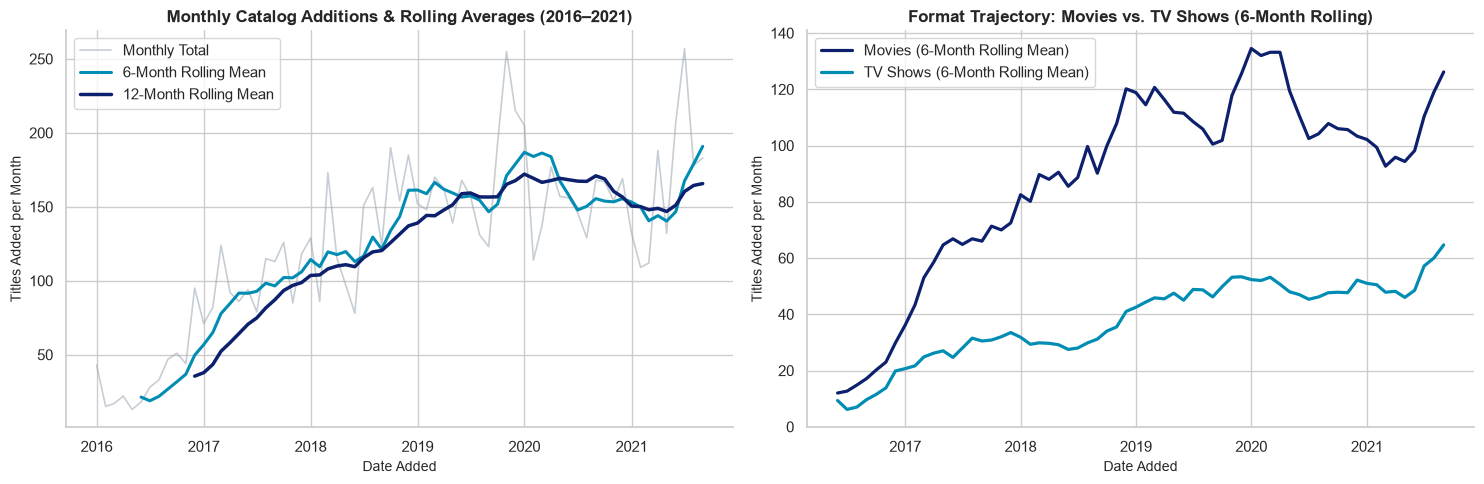

In [2]:
pre_2016_titles = monthly_counts.loc[:"2015-12", "Total"].sum()
modern_monthly = monthly_counts.loc["2016-01":].copy()
modern_titles = modern_monthly["Total"].sum()

print(f"Pre-2016 titles (96 months): {pre_2016_titles} ({pre_2016_titles / len(df_trend) * 100:.2f}%)")
print(f"2016–2021 titles (69 months): {modern_titles} ({modern_titles / len(df_trend) * 100:.2f}%)")

modern_monthly["rolling_6m_total"] = modern_monthly["Total"].rolling(6).mean()
modern_monthly["rolling_12m_total"] = modern_monthly["Total"].rolling(12).mean()
modern_monthly["rolling_6m_movie"] = modern_monthly["Movie"].rolling(6).mean()
modern_monthly["rolling_6m_tv"] = modern_monthly["TV Show"].rolling(6).mean()

periods = {
    "2016–2017 (Early Scale-Up)": modern_monthly.loc["2016-01":"2017-12"],
    "2018–2019 (Peak Expansion)": modern_monthly.loc["2018-01":"2019-12"],
    "2020–2021 (Pandemic & Plateau)": modern_monthly.loc["2020-01":"2021-09"],
}
regime_summary = pd.DataFrame([
    {
        "period": label,
        "months": len(sub),
        "avg_monthly_total": round(sub["Total"].mean(), 2),
        "avg_monthly_movies": round(sub["Movie"].mean(), 2),
        "avg_monthly_tv": round(sub["TV Show"].mean(), 2),
        "tv_share_%": round(sub["TV Show"].sum() / sub["Total"].sum() * 100, 2),
    }
    for label, sub in periods.items()
])
display(regime_summary)

peak_12m_idx = modern_monthly["rolling_12m_total"].idxmax()
print(f"Peak 12-month rolling average: {modern_monthly['rolling_12m_total'].max():.2f} titles/month at {peak_12m_idx}")
print(f"Latest 12-month rolling average (2021-09): {modern_monthly['rolling_12m_total'].iloc[-1]:.2f} titles/month")

x_dates = modern_monthly.index.to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(x_dates, modern_monthly["Total"], color="#9aa5b1", alpha=0.55, linewidth=1.2, label="Monthly Total")
axes[0].plot(x_dates, modern_monthly["rolling_6m_total"], color="#008cb3", linewidth=2.2, label="6-Month Rolling Mean")
axes[0].plot(x_dates, modern_monthly["rolling_12m_total"], color="#0c206d", linewidth=2.5, label="12-Month Rolling Mean")
axes[0].set_title("Monthly Catalog Additions & Rolling Averages (2016–2021)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Date Added", fontsize=10)
axes[0].set_ylabel("Titles Added per Month", fontsize=10)
axes[0].legend()

axes[1].plot(x_dates, modern_monthly["rolling_6m_movie"], color="#0c206d", linewidth=2.3, label="Movies (6-Month Rolling Mean)")
axes[1].plot(x_dates, modern_monthly["rolling_6m_tv"], color="#008cb3", linewidth=2.3, label="TV Shows (6-Month Rolling Mean)")
axes[1].set_title("Format Trajectory: Movies vs. TV Shows (6-Month Rolling)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Date Added", fontsize=10)
axes[1].set_ylabel("Titles Added per Month", fontsize=10)
axes[1].legend()

sns.despine()
plt.tight_layout()
plt.show()

### Checkpoint: Key Takeaways Before Forecasting

- **Modeling Window Selection:** Roughly **98.43%** (`8,645` titles) of catalog additions occurred across the **69 months** from `2016-01` to `2021-09`, whereas `2008–2015` (`96` months) accounts for only **1.57%** (`138` titles). Restricting training to `2016–2021` avoids downward bias from the pre-streaming era.
- **Growth-to-Plateau Transition:** Monthly additions scaled from **67.12/month** (`2016–2017`) to **152.38/month** (`2018–2019`), peaking at a 12-month rolling average of **172.08 titles/month** in `2020-01` before stabilizing around **165.67 titles/month** by `2021-09` (**160.81/month** across `2020–2021`).
- **Format Divergence:** While monthly movie additions leveled off between `2018–2019` (**110.67/month**) and `2020–2021` (**108.43/month**), TV Show additions grew by **+25.6%** (**41.71** to **52.38/month**), lifting `tv_share_%` from **27.37%** to **32.57%** and justifying separate forecasting models for `Movies` and `TV Shows`.

## 3. Forecasting Models & Chronological Backtesting

Split `modern_monthly` (`2016-01` to `2021-09`) chronologically into a **57-month training window** (`2016-01` to `2020-09`) and a **12-month out-of-sample test window** (`2020-10` to `2021-09`), then benchmark five forecasting models using **MAE** and **RMSE** across `Total`, `Movie`, and `TV Show` additions.

In [3]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

train_df = modern_monthly.iloc[:-12].copy()
test_df = modern_monthly.iloc[-12:].copy()

print("Train window:", train_df.index.min(), "to", train_df.index.max(), f"({len(train_df)} months)")
print("Test window :", test_df.index.min(), "to", test_df.index.max(), f"({len(test_df)} months)")

t_train = np.arange(len(train_df), dtype=float)
t_test = np.arange(len(train_df), len(train_df) + len(test_df), dtype=float)
m_train = train_df.index.month.to_numpy()
m_test = test_df.index.month.to_numpy()

def make_features(t, months, mode):
    if mode == "linear":
        return t.reshape(-1, 1)
    if mode == "log_growth":
        return np.log1p(t).reshape(-1, 1)
    if mode == "poly2_ridge":
        t_scaled = t / 60.0
        return np.column_stack([t_scaled, t_scaled ** 2])
    if mode == "log_seasonal":
        return np.column_stack([
            np.log1p(t),
            np.sin(2 * np.pi * months / 12.0),
            np.cos(2 * np.pi * months / 12.0),
        ])
    raise ValueError(f"Unknown mode: {mode}")

eval_rows = []
for target in ["Total", "Movie", "TV Show"]:
    y_train = train_df[target].to_numpy(dtype=float)
    y_test = test_df[target].to_numpy(dtype=float)

    pred_ma12 = np.full_like(y_test, y_train[-12:].mean())
    eval_rows.append({
        "series": target,
        "model": "Trailing 12M Mean (Baseline)",
        "MAE": round(mean_absolute_error(y_test, pred_ma12), 2),
        "RMSE": round(root_mean_squared_error(y_test, pred_ma12), 2),
    })

    candidates = [
        ("Linear Trend", "linear", LinearRegression()),
        ("Log-Growth Trend", "log_growth", LinearRegression()),
        ("Poly-2 Ridge", "poly2_ridge", Ridge(alpha=1.0)),
        ("Log-Growth + Seasonality", "log_seasonal", LinearRegression()),
    ]
    for model_name, mode, est in candidates:
        X_tr = make_features(t_train, m_train, mode)
        X_te = make_features(t_test, m_test, mode)
        est.fit(X_tr, y_train)
        preds = np.clip(est.predict(X_te), 0, None)
        eval_rows.append({
            "series": target,
            "model": model_name,
            "MAE": round(mean_absolute_error(y_test, preds), 2),
            "RMSE": round(root_mean_squared_error(y_test, preds), 2),
        })

backtest_df = pd.DataFrame(eval_rows)
display(backtest_df)

Train window: 2016-01 to 2020-09 (57 months)
Test window : 2020-10 to 2021-09 (12 months)


,series,model,MAE,RMSE
0,Total,Trailing 12M Mean (Baseline),31.65,40.66
1,Total,Linear Trend,53.82,60.78
2,Total,Log-Growth Trend,29.56,39.62
3,Total,Poly-2 Ridge,48.38,55.71
4,Total,Log-Growth + Seasonality,39.25,48.17
5,Movie,Trailing 12M Mean (Baseline),22.17,28.51
6,Movie,Linear Trend,44.72,49.48
7,Movie,Log-Growth Trend,23.03,29.01
8,Movie,Poly-2 Ridge,39.59,44.21
9,Movie,Log-Growth + Seasonality,28.99,36.06


## 4. Future Content Projections (2021 Q4 – 2023)

Refit the winning **Log-Growth Trend** model on the full 69-month modern window (`2016-01` to `2021-09`) separately for `Movies` and `TV Shows`, project monthly and annual additions through `2023-12` alongside a `Linear Trend` upper reference, and visualize historical vs. forecasted trajectories.

,year,status,Movies,TV_Shows,Total_Log,Total_Linear_Ref,TV_Share_%
0,2019,Actual (12M),1422,590,2012,2012,29.32
1,2020,Actual (12M),1284,595,1879,1879,31.67
2,2021,9M Actual + 3M Forecast,1361,664,2025,2114,32.78
3,2022,Forecast (12M),1517,654,2171,2666,30.12
4,2023,Forecast (12M),1578,680,2258,2986,30.10


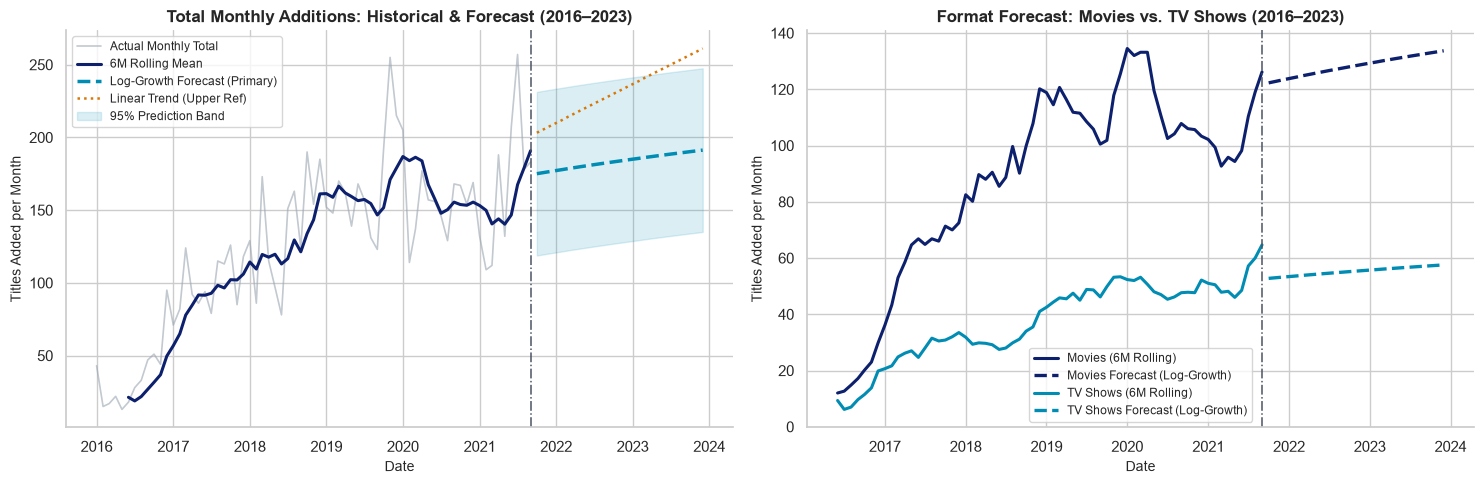

In [4]:
t_full = np.arange(len(modern_monthly), dtype=float)
X_full_log = np.log1p(t_full).reshape(-1, 1)
X_full_lin = t_full.reshape(-1, 1)

future_idx = pd.period_range(start="2021-10", end="2023-12", freq="M")
t_future = np.arange(len(modern_monthly), len(modern_monthly) + len(future_idx), dtype=float)
X_fut_log = np.log1p(t_future).reshape(-1, 1)
X_fut_lin = t_future.reshape(-1, 1)

forecast_data = {}
resid_stds = {}

for target in ["Movie", "TV Show"]:
    y_full = modern_monthly[target].to_numpy(dtype=float)
    model_log = LinearRegression().fit(X_full_log, y_full)
    model_lin = LinearRegression().fit(X_full_lin, y_full)

    fitted_log = model_log.predict(X_full_log)
    resid_stds[target] = float(np.std(y_full - fitted_log, ddof=2))

    forecast_data[f"{target}_log"] = np.clip(model_log.predict(X_fut_log), 0, None)
    forecast_data[f"{target}_lin"] = np.clip(model_lin.predict(X_fut_lin), 0, None)

forecast_df = pd.DataFrame(forecast_data, index=future_idx)
forecast_df.index.name = "year_month"
forecast_df["Total_log"] = forecast_df["Movie_log"] + forecast_df["TV Show_log"]
forecast_df["Total_lin"] = forecast_df["Movie_lin"] + forecast_df["TV Show_lin"]
forecast_df["tv_share_log_%"] = (forecast_df["TV Show_log"] / forecast_df["Total_log"] * 100).round(2)

act_2021 = modern_monthly.loc["2021-01":"2021-09", ["Movie", "TV Show", "Total"]].sum()
q4_2021_log = forecast_df.loc["2021-10":"2021-12", ["Movie_log", "TV Show_log", "Total_log"]].sum().to_numpy()
q4_2021_lin = forecast_df.loc["2021-10":"2021-12", ["Movie_lin", "TV Show_lin", "Total_lin"]].sum().to_numpy()

yr_2022_log = forecast_df.loc["2022-01":"2022-12", ["Movie_log", "TV Show_log", "Total_log"]].sum().to_numpy()
yr_2022_lin = forecast_df.loc["2022-01":"2022-12", ["Movie_lin", "TV Show_lin", "Total_lin"]].sum().to_numpy()

yr_2023_log = forecast_df.loc["2023-01":"2023-12", ["Movie_log", "TV Show_log", "Total_log"]].sum().to_numpy()
yr_2023_lin = forecast_df.loc["2023-01":"2023-12", ["Movie_lin", "TV Show_lin", "Total_lin"]].sum().to_numpy()

annual_proj = pd.DataFrame([
    {"year": 2019, "status": "Actual (12M)", "Movies": 1422, "TV_Shows": 590, "Total_Log": 2012, "Total_Linear_Ref": 2012, "TV_Share_%": round(590 / 2012 * 100, 2)},
    {"year": 2020, "status": "Actual (12M)", "Movies": 1284, "TV_Shows": 595, "Total_Log": 1879, "Total_Linear_Ref": 1879, "TV_Share_%": round(595 / 1879 * 100, 2)},
    {
        "year": 2021,
        "status": "9M Actual + 3M Forecast",
        "Movies": int(round(act_2021["Movie"] + q4_2021_log[0])),
        "TV_Shows": int(round(act_2021["TV Show"] + q4_2021_log[1])),
        "Total_Log": int(round(act_2021["Total"] + q4_2021_log[2])),
        "Total_Linear_Ref": int(round(act_2021["Total"] + q4_2021_lin[2])),
        "TV_Share_%": round((act_2021["TV Show"] + q4_2021_log[1]) / (act_2021["Total"] + q4_2021_log[2]) * 100, 2),
    },
    {
        "year": 2022,
        "status": "Forecast (12M)",
        "Movies": int(round(yr_2022_log[0])),
        "TV_Shows": int(round(yr_2022_log[1])),
        "Total_Log": int(round(yr_2022_log[2])),
        "Total_Linear_Ref": int(round(yr_2022_lin[2])),
        "TV_Share_%": round(yr_2022_log[1] / yr_2022_log[2] * 100, 2),
    },
    {
        "year": 2023,
        "status": "Forecast (12M)",
        "Movies": int(round(yr_2023_log[0])),
        "TV_Shows": int(round(yr_2023_log[1])),
        "Total_Log": int(round(yr_2023_log[2])),
        "Total_Linear_Ref": int(round(yr_2023_lin[2])),
        "TV_Share_%": round(yr_2023_log[1] / yr_2023_log[2] * 100, 2),
    },
])

display(annual_proj)

hist_dates = modern_monthly.index.to_timestamp()
fut_dates = forecast_df.index.to_timestamp()
total_resid_std = np.sqrt(resid_stds["Movie"]**2 + resid_stds["TV Show"]**2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(hist_dates, modern_monthly["Total"], color="#9aa5b1", alpha=0.6, linewidth=1.2, label="Actual Monthly Total")
axes[0].plot(hist_dates, modern_monthly["Total"].rolling(6).mean(), color="#0c206d", linewidth=2.2, label="6M Rolling Mean")
axes[0].plot(fut_dates, forecast_df["Total_log"], color="#008cb3", linewidth=2.5, linestyle="--", label="Log-Growth Forecast (Primary)")
axes[0].plot(fut_dates, forecast_df["Total_lin"], color="#d97706", linewidth=1.8, linestyle=":", label="Linear Trend (Upper Ref)")
axes[0].fill_between(
    fut_dates,
    np.clip(forecast_df["Total_log"] - 1.96 * total_resid_std, 0, None),
    forecast_df["Total_log"] + 1.96 * total_resid_std,
    color="#008cb3",
    alpha=0.14,
    label="95% Prediction Band",
)
axes[0].axvline(pd.Timestamp("2021-09-01"), color="#4b5563", linestyle="-.", linewidth=1.1)
axes[0].set_title("Total Monthly Additions: Historical & Forecast (2016–2023)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Date", fontsize=10)
axes[0].set_ylabel("Titles Added per Month", fontsize=10)
axes[0].legend(fontsize=8.5)

axes[1].plot(hist_dates, modern_monthly["Movie"].rolling(6).mean(), color="#0c206d", linewidth=2.2, label="Movies (6M Rolling)")
axes[1].plot(fut_dates, forecast_df["Movie_log"], color="#0c206d", linewidth=2.4, linestyle="--", label="Movies Forecast (Log-Growth)")
axes[1].plot(hist_dates, modern_monthly["TV Show"].rolling(6).mean(), color="#008cb3", linewidth=2.2, label="TV Shows (6M Rolling)")
axes[1].plot(fut_dates, forecast_df["TV Show_log"], color="#008cb3", linewidth=2.4, linestyle="--", label="TV Shows Forecast (Log-Growth)")
axes[1].axvline(pd.Timestamp("2021-09-01"), color="#4b5563", linestyle="-.", linewidth=1.1)
axes[1].set_title("Format Forecast: Movies vs. TV Shows (2016–2023)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Date", fontsize=10)
axes[1].set_ylabel("Titles Added per Month", fontsize=10)
axes[1].legend(fontsize=8.5)

sns.despine()
plt.tight_layout()
plt.show()

## 5. Summary, Quantitative Evidence & Forecasting Limitations

- **Time-Series Construction & Window Selection:** Aggregated **8,783** catalog additions (`2008-01-01` to `2021-09-25`) into a continuous **165-month** time series (`monthly_counts`), identifying that `2021` contains only **9 recorded months** (`1,498` titles) and that **98.43%** (`8,645` titles) of additions occurred within the **69-month** modern streaming era (`2016-01` to `2021-09`). Separating growth phases confirmed a shift from rapid expansion (`67.12` titles/month in `2016–2017` to `152.38`/month in `2018–2019`) to a high-volume plateau (`160.81`/month in `2020–2021`, peaking at a 12-month rolling average of **172.08**/month in `2020-01` and **165.67**/month in `2021-09`), alongside a **+25.6%** rise in monthly TV Show additions (`41.71` to `52.38`/month).
- **Chronological Backtesting & Model Selection:** Evaluated five candidate models using a leak-free **57-month train** (`2016-01` to `2020-09`) / **12-month out-of-sample test** (`2020-10` to `2021-09`) split:
  - **Total Additions:** `Log-Growth Trend` achieved the lowest error (**MAE = 29.56**, **RMSE = 39.62**), outperforming the `Trailing 12M Mean` baseline (**MAE = 31.65**, **RMSE = 40.66**) and reducing MAE by **45.1%** compared to `Linear Trend` (**MAE = 53.82**, **RMSE = 60.78**).
  - **Movies vs. TV Shows:** `Log-Growth Trend` maintained strong accuracy on `Movies` (**MAE = 23.03**, **RMSE = 29.01** vs. `Linear Trend` **MAE = 44.72**), while all models converged tightly on `TV Shows` within **13.61–14.12 MAE** (`Poly-2 Ridge` **RMSE = 16.11**, `Log-Growth` **MAE = 14.11**).
- **2021–2023 Content Projections:** Refitting `Log-Growth Trend` across all **69** modern months projects **527** titles in `2021 Q4` (`368` Movies, `159` TV Shows), bringing full-year **2021** to **2,025** titles (`1,361` Movies, `664` TV Shows; **32.78%** TV share). Annual additions are projected to reach **2,171** titles in **2022** (`1,517` Movies, `654` TV Shows; **30.12%** TV share) and **2,258** titles in **2023** (`1,578` Movies, `680` TV Shows; **30.10%** TV share)—representing measured **+4.0%** annual growth rather than the inflated **2,666** (`2022`) and **2,986** (`2023`) linear extrapolation, with monthly residual standard deviations of **26.21** (`Movies`) and **11.69** (`TV Shows`).
- **Limitations & Future Enhancements:** Univariate time-series trends capture historical addition momentum but cannot observe exogenous drivers such as annual content budgets, pandemic-induced production delays (`2020–2021`), regional licensing expirations, or shifting subscriber churn targets. Incorporating external macroeconomic/production indicators or multi-year seasonal ARIMA/Prophet models with wider historical post-2021 data would further tighten prediction intervals.